# FIAP — IA — Fase 3 — Machine Learning no agronegócio

**Alunos:** Edemir Sufiatti (RM571375), Carlos Magnus Costa Amaral (RM573978), Georgia Mendes Rocha (RM573281), Marina Leme Soares (RM570461).  
**Projeto:** FarmTech Solutions.

- **Repositório Git:** [github.com/EdeSufiatti/FASE3_AT1_Farmtech_dashboard](https://github.com/EdeSufiatti/FASE3_AT1_Farmtech_dashboard)
- **Vídeo demonstrativo (≤5 min):** [https://youtu.be/Ds_Ag9mhRvE](https://youtu.be/Ds_Ag9mhRvE)

Este Jupyter replica o fluxo da página Streamlit **`src/frontend/pages/notebook_ml.py`** (mesmos hiperparâmetros, partições train/test e lógica de fallback Oracle → CSV).

- **Parte A — Sensores Fase 2 (bomba):** Oracle **`SENSORES_FARMTECH`**; fallback **`src/dados/historico_irrigacao.csv`**.
- **Parte B — Produtos agrícolas (culturas):** **`src/dados/Atividade_Cap10_produtos_agricolas.csv`** (variáveis do enunciado: `N, P, K, temperatura, umidade, pH, chuva, label`); alvo multiclasse **`label`**.


In [4]:
from pathlib import Path
import warnings
import os

import oracledb
from dotenv import load_dotenv

import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from IPython import get_ipython
from IPython.display import display

warnings.filterwarnings("ignore")

try:
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic("matplotlib", "inline")
except Exception:
    pass

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 120


def encontrar_raiz_repo() -> Path:
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / ".env").is_file() and (cand / "src").is_dir():
            return cand
    return aqui


REPO = encontrar_raiz_repo()
CSV_PATH = REPO / "src" / "dados" / "historico_irrigacao.csv"
AGRI_CSV_PATH = REPO / "src" / "dados" / "Atividade_Cap10_produtos_agricolas.csv"
load_dotenv(REPO / ".env", override=True)


def carregar_oracle() -> pd.DataFrame:
    user = os.getenv("ORACLE_USER")
    pwd = os.getenv("ORACLE_PASS")
    dsn = os.getenv("ORACLE_DSN")
    if not (user and pwd and dsn):
        raise ValueError("Variaveis ORACLE_USER/ORACLE_PASS/ORACLE_DSN ausentes.")
    with oracledb.connect(user=user, password=pwd, dsn=dsn) as conn:
        query = (
            "SELECT TS_ISO, UMIDADE, TEMP_C, PH_CORR, N, P, K, BOMBA_FW "
            "FROM SENSORES_FARMTECH"
        )
        return pd.read_sql(query, conn)


def carregar_csv(path: Path) -> pd.DataFrame:
    if not path.is_file():
        raise FileNotFoundError(f"CSV nao encontrado: {path}")
    return pd.read_csv(path)


def preparar(df: pd.DataFrame) -> pd.DataFrame:
    # Igual a _preparar em notebook_ml.py.
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    rename = {"n": "N", "p": "P", "k": "K"}
    for a, b in rename.items():
        if a in df.columns and b not in df.columns:
            df = df.rename(columns={a: b})
    required = ["umidade", "temp_c", "ph_corr", "N", "P", "K", "bomba_fw"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Colunas ausentes: {missing}")
    df = df.dropna(subset=required).copy()
    df["bomba_fw"] = pd.to_numeric(df["bomba_fw"], errors="coerce").fillna(0).astype(int).clip(0, 1)
    df["temp_c"] = pd.to_numeric(df["temp_c"], errors="coerce")
    df["umidade"] = pd.to_numeric(df["umidade"], errors="coerce")
    df["ph_corr"] = pd.to_numeric(df["ph_corr"], errors="coerce")
    df = df.dropna(subset=["temp_c", "umidade", "ph_corr"])
    return df


def preparar_produtos(df: pd.DataFrame) -> pd.DataFrame:
    # Igual a _preparar_produtos em notebook_ml.py.
    # Esquema do CSV: N,P,K,temperature,humidity,ph,rainfall,label.
    df = df.copy()
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    rename = {
        "temperature": "temp_c",
        "humidity": "umidade",
        "ph": "ph_corr",
        "rainfall": "chuva",
        "n": "N",
        "p": "P",
        "k": "K",
        "nitrogen": "N",
        "phosphorous": "P",
        "phosphorus": "P",
        "potassium": "K",
        "crop": "label",
        "crop_type": "label",
    }
    df = df.rename(columns={k: v for k, v in rename.items() if k in df.columns and v not in df.columns})
    required = ["temp_c", "umidade", "ph_corr", "chuva", "N", "P", "K", "label"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Colunas ausentes na base de produtos: {missing}")
    for col in ["temp_c", "umidade", "ph_corr", "chuva", "N", "P", "K"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["label"] = df["label"].astype(str).str.strip()
    df = df.dropna(subset=required).copy()
    return df


try:
    raw_a = carregar_oracle()
    FONTE_DADOS = "oracle"
    err_oracle = None
except Exception as e:
    err_oracle = str(e)
    raw_a = carregar_csv(CSV_PATH)
    FONTE_DADOS = "csv_fallback"

df = preparar(raw_a)

print("Repositorio:", REPO)
print("Fonte Parte A:", FONTE_DADOS, "| CSV fallback:", CSV_PATH)
if err_oracle:
    print("Oracle indisponivel:", err_oracle)


Repositorio: C:\Users\Georgia\Documents\FIAP_IA\Fase 3\FASE3_AT1_Farmtech_dashboard-main
Fonte Parte A: oracle | CSV fallback: C:\Users\Georgia\Documents\FIAP_IA\Fase 3\FASE3_AT1_Farmtech_dashboard-main\src\dados\historico_irrigacao.csv


## Parte A — Sensores Fase 2 (bomba) + dados de cultura
A Parte A combina dois blocos:

1. **Sensores Fase 2** — `bomba_fw` como alvo, EDA, K-Means (k=3) e cinco classificadores.
2. **Dados de cultura reais** — leitura de **`src/dados/Atividade_Cap10_produtos_agricolas.csv`** (variáveis do enunciado: **N, P, K, temperatura, umidade, pH, chuva, label**) com amostra, distribuição, perfil real por cultura e dispersão temperatura × umidade — apresentados em paralelo aos sensores.

### 1. Amostra e estatísticas (`st.subheader` equivalente)

In [5]:
display(df.head())
display(df.describe().round(2))
print('Distribuicao de classes (bomba_fw):')
print(df['bomba_fw'].value_counts().sort_index())


,ts_iso,umidade,temp_c,ph_corr,N,P,K,bomba_fw
0,2026-05-03T20:12:04,87.0,27.9,5.347,1.0,1.0,1.0,0
1,2026-05-03T20:12:13,87.0,29.0,5.347,1.0,1.0,1.0,0
2,2026-05-03T20:12:21,84.5,30.3,5.347,1.0,1.0,1.0,0
3,2026-05-03T20:12:29,83.0,31.0,5.347,1.0,1.0,1.0,0
4,2026-05-03T20:12:37,79.5,31.6,5.347,1.0,1.0,1.0,1


,umidade,temp_c,ph_corr,N,P,K,bomba_fw
count,153.00,153.00,153.00,153.00,153.00,153.00,153.00
mean,75.52,28.71,7.25,0.87,0.85,0.67,0.52
std,10.44,4.16,1.83,0.34,0.36,0.47,0.50
min,39.50,14.40,4.65,0.00,0.00,0.00,0.00
25%,73.00,24.00,5.35,1.00,1.00,0.00,0.00
50%,80.00,29.60,8.17,1.00,1.00,1.00,1.00
75%,82.50,31.00,8.67,1.00,1.00,1.00,1.00
max,87.00,36.00,10.38,1.00,1.00,1.00,1.00


Distribuicao de classes (bomba_fw):
bomba_fw
0    73
1    80
Name: count, dtype: int64


### 2. EDA — espelho de `_plot_eda()` (histograma, dispersão contínua, pH, pizza, barras agrupadas, correlação)


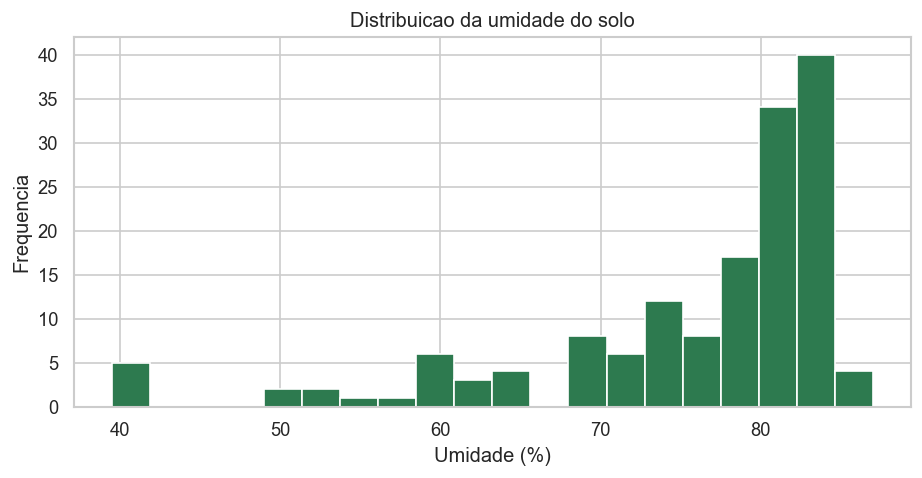

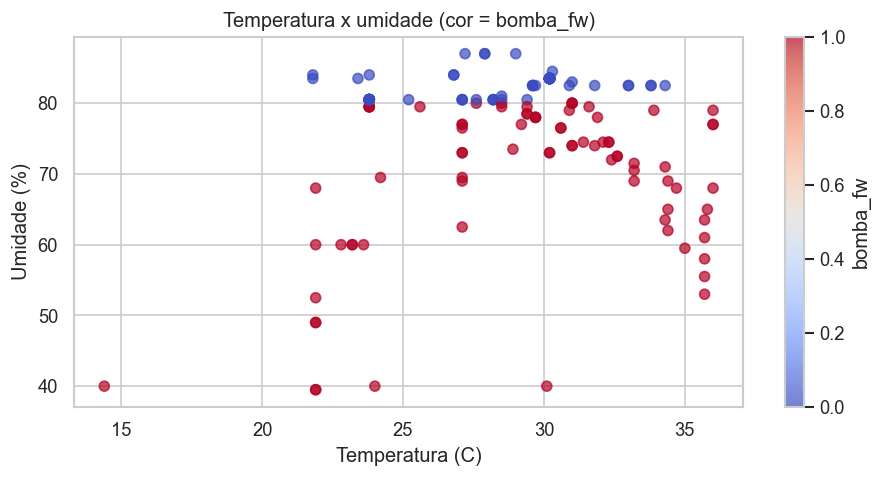

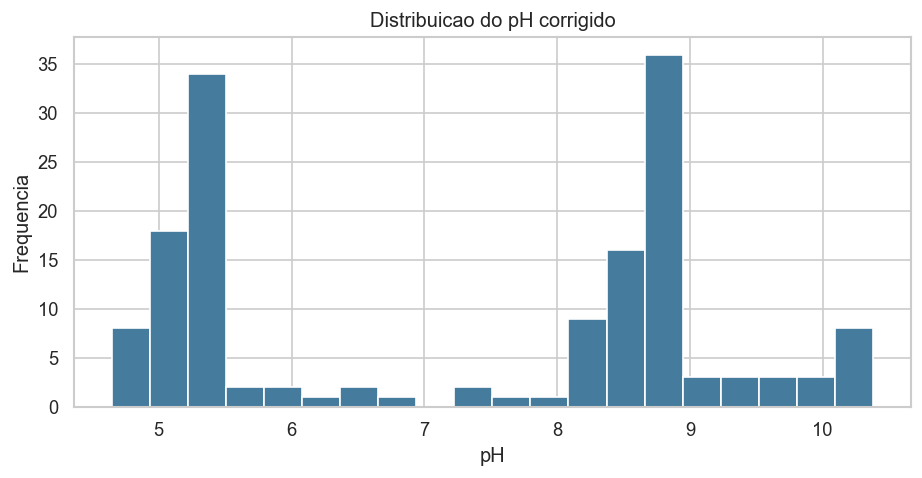

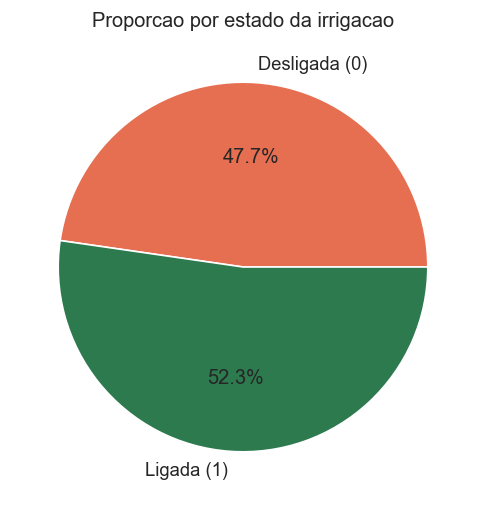

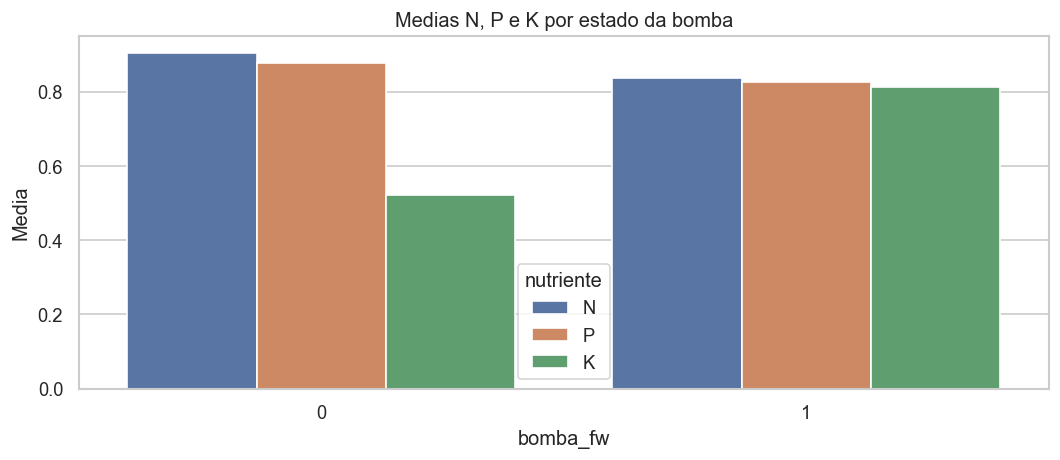

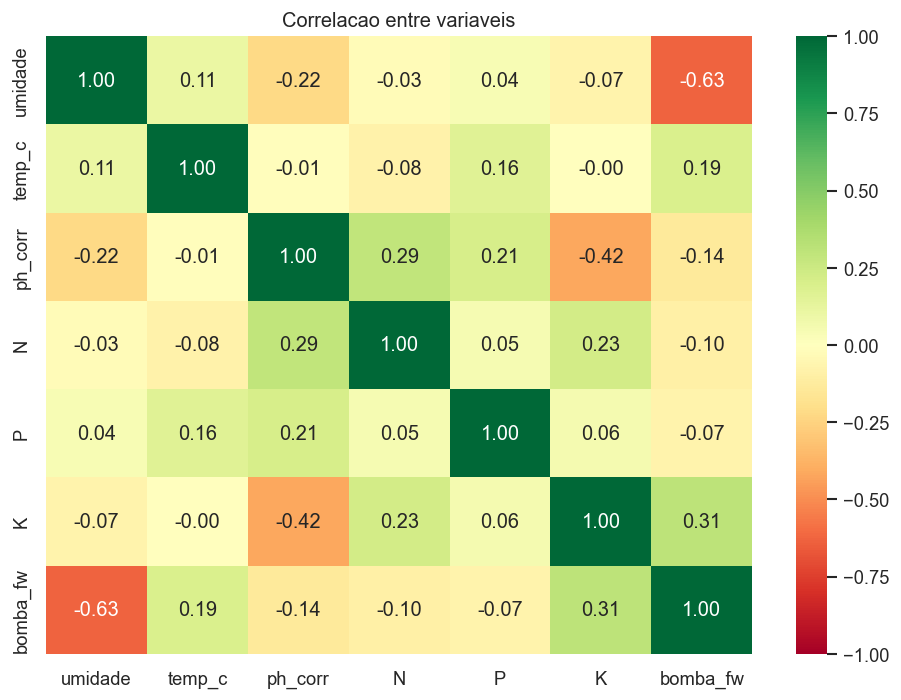

In [6]:
fig1 = plt.figure()
plt.hist(df["umidade"], bins=20, color="#2d7a4f", edgecolor="white")
plt.title("Distribuicao da umidade do solo")
plt.xlabel("Umidade (%)")
plt.ylabel("Frequencia")
plt.show()

fig2 = plt.figure()
sc = plt.scatter(df["temp_c"], df["umidade"], c=df["bomba_fw"], cmap="coolwarm", alpha=0.7, vmin=0, vmax=1)
plt.title("Temperatura x umidade (cor = bomba_fw)")
plt.xlabel("Temperatura (C)")
plt.ylabel("Umidade (%)")
plt.colorbar(sc, label="bomba_fw")
plt.show()

fig3 = plt.figure()
plt.hist(df["ph_corr"], bins=20, color="#457b9d", edgecolor="white")
plt.title("Distribuicao do pH corrigido")
plt.xlabel("pH")
plt.ylabel("Frequencia")
plt.show()

vc = df["bomba_fw"].value_counts().sort_index()
labels_pie = ["Desligada (0)", "Ligada (1)"] if len(vc) == 2 else [str(i) for i in vc.index]
colors_pie = ["#e76f51", "#2d7a4f"][: len(vc)]
plt.figure(figsize=(5, 5))
plt.pie(vc.values, labels=labels_pie, autopct="%1.1f%%", colors=colors_pie)
plt.title("Proporcao por estado da irrigacao")
plt.show()

medias = df.groupby("bomba_fw")[["N", "P", "K"]].mean().reset_index()
medias["bomba_fw"] = medias["bomba_fw"].astype(str)
mm = medias.melt(id_vars=["bomba_fw"], var_name="nutriente", value_name="media")
plt.figure()
sns.barplot(data=mm, x="bomba_fw", y="media", hue="nutriente")
plt.title("Medias N, P e K por estado da bomba")
plt.xlabel("bomba_fw")
plt.ylabel("Media")
plt.legend(title="nutriente")
plt.tight_layout()
plt.show()

corr = df[["umidade", "temp_c", "ph_corr", "N", "P", "K", "bomba_fw"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1)
plt.title("Correlacao entre variaveis")
plt.tight_layout()
plt.show()


### 3. Referência de culturas e K-Means (k=3) — `_secao_cluster()`
Tabela de referência + centroides na escala original; dispersão temperatura × umidade com marcadores **X** nos centroides (como Plotly).


,cultura,umidade_min,umidade_max,temp_min,temp_max,ph_min,ph_max
0,Milho,55,75,18,30,5.8,7.0
1,Soja,50,70,20,28,5.5,6.8
2,Tomate,60,80,20,28,6.0,6.8


,umidade,temp_c,ph_corr,cluster
0,78.07,30.31,8.85,0
1,78.20,28.54,5.40,1
2,53.09,22.87,8.86,2


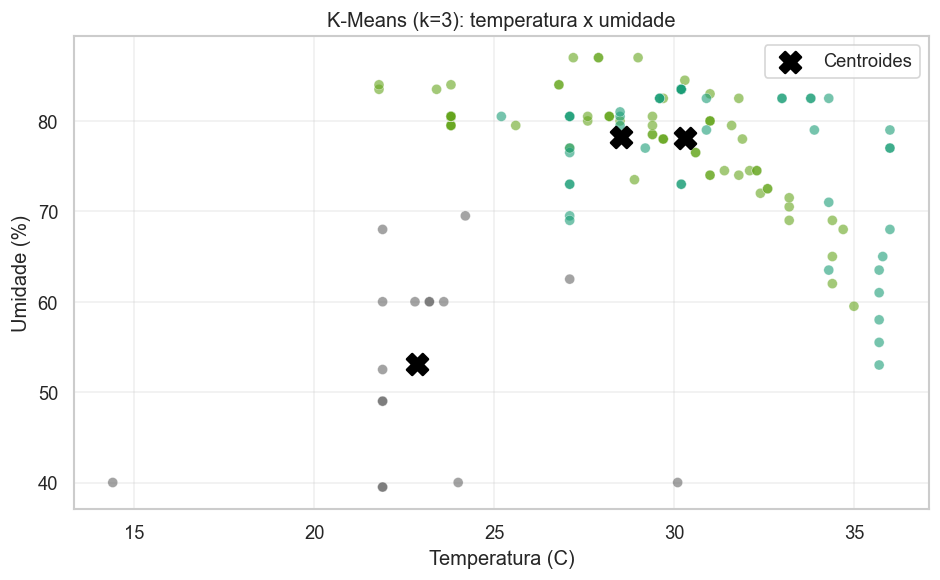

In [7]:
referencia = pd.DataFrame(
    {
        "cultura": ["Milho", "Soja", "Tomate"],
        "umidade_min": [55, 50, 60],
        "umidade_max": [75, 70, 80],
        "temp_min": [18, 20, 20],
        "temp_max": [30, 28, 28],
        "ph_min": [5.8, 5.5, 6.0],
        "ph_max": [7.0, 6.8, 6.8],
    }
)
display(referencia)

X_clima = df[["umidade", "temp_c", "ph_corr"]].values.astype(float)
scaler = StandardScaler().fit(X_clima)
Z = scaler.transform(X_clima)
km = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = km.fit_predict(Z)
centros = pd.DataFrame(
    scaler.inverse_transform(km.cluster_centers_),
    columns=["umidade", "temp_c", "ph_corr"],
)
centros["cluster"] = range(3)
display(centros.round(2))

cmap = mpl_cm.get_cmap("Dark2")
colors_k = cmap(clusters / max(clusters.max(), 1))
plt.figure(figsize=(8, 5))
plt.scatter(df["temp_c"], df["umidade"], c=colors_k, alpha=0.6, s=36, edgecolors="white", linewidths=0.3)
plt.scatter(
    centros["temp_c"],
    centros["umidade"],
    c="black",
    marker="X",
    s=160,
    linewidths=1.5,
    label="Centroides",
)
plt.title("K-Means (k=3): temperatura x umidade")
plt.xlabel("Temperatura (C)")
plt.ylabel("Umidade (%)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3.b. Dados de cultura reais — `Atividade_Cap10_produtos_agricolas.csv`
Carrega o CSV de **produtos agrícolas** (variáveis do enunciado: **N, P, K, temperatura, umidade, pH, chuva, label**) e apresenta, ainda na **Parte A**:

- **Amostra e estatísticas** das culturas reais (substituem a tabela de referência fictícia "Milho/Soja/Tomate" por valores observados);
- **Distribuição** de classes (`label`);
- **Perfil real por cultura** (média de N, P, K, `temp_c`, `umidade`, `ph_corr`, `chuva`) — calculado a partir do dataset, não hard-coded;
- **Dispersão temperatura × umidade** colorida por cultura, comparável visualmente ao K-Means de sensores acima.

Fonte dados de cultura (Parte A): C:\Users\Georgia\Documents\FIAP_IA\Fase 3\FASE3_AT1_Farmtech_dashboard-main\src\dados\Atividade_Cap10_produtos_agricolas.csv
Linhas apos preparo: 2200


,N,P,K,temp_c,umidade,ph_corr,chuva,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


,N,P,K,temp_c,umidade,ph_corr,chuva
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


Distribuicao de classes (label/cultura):
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64
Perfil real por cultura (medias das variaveis do enunciado):


,label,N,P,K,temp_c,umidade,ph_corr,chuva
0,apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
1,banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
2,blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
3,chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
4,coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
5,coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
6,cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
7,grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
8,jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79
9,kidneybeans,20.75,67.54,20.05,20.12,21.61,5.75,105.92


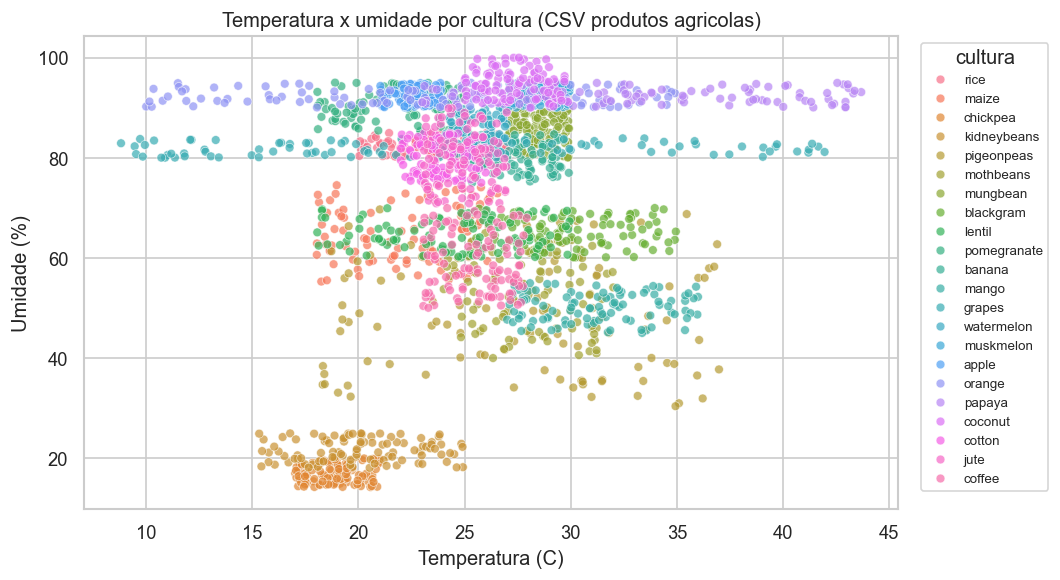

Tres culturas mais frequentes (escolhidas para o perfil ideal): ['rice', 'maize', 'chickpea']


,label,N,P,K,temp_c,umidade,ph_corr,chuva
0,chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
1,maize,77.76,48.44,19.79,22.39,65.09,6.25,84.77
2,rice,79.89,47.58,39.87,23.69,82.27,6.43,236.18


In [8]:
dfa_pre = preparar_produtos(carregar_csv(AGRI_CSV_PATH))
print("Fonte dados de cultura (Parte A):", AGRI_CSV_PATH)
print("Linhas apos preparo:", len(dfa_pre))

display(dfa_pre.head())
display(dfa_pre.describe().round(2))

print("Distribuicao de classes (label/cultura):")
print(dfa_pre["label"].value_counts())

perfil_culturas = (
    dfa_pre.groupby("label", as_index=False)[
        ["N", "P", "K", "temp_c", "umidade", "ph_corr", "chuva"]
    ]
    .mean()
    .round(2)
    .sort_values("label")
)
print("Perfil real por cultura (medias das variaveis do enunciado):")
display(perfil_culturas)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=dfa_pre, x="temp_c", y="umidade", hue="label", alpha=0.7, s=28)
plt.title("Temperatura x umidade por cultura (CSV produtos agricolas)")
plt.xlabel("Temperatura (C)")
plt.ylabel("Umidade (%)")
plt.legend(title="cultura", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

top3_a = dfa_pre["label"].value_counts().head(3).index.tolist()
print("Tres culturas mais frequentes (escolhidas para o perfil ideal):", top3_a)
display(
    perfil_culturas[perfil_culturas["label"].isin(top3_a)]
    .reset_index(drop=True)
)

### 4. Cinco modelos (`_secao_modelos`) — hiperparâmetros idênticos ao Streamlit


In [9]:
FEATURES = ["umidade", "temp_c", "ph_corr", "N", "P", "K"]
TARGET = "bomba_fw"

X = df[FEATURES].values.astype(float)
y = df[TARGET].values.astype(int)

X_scaled = StandardScaler().fit_transform(X)
split_kwargs = {"test_size": 0.25, "random_state": 42}
if pd.Series(y).value_counts().min() >= 2:
    split_kwargs["stratify"] = y
try:
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, **split_kwargs)
except ValueError:
    split_kwargs.pop("stratify", None)
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, **split_kwargs)

modelos = {
    "Regressao Logistica": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, random_state=42, max_depth=8),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42, max_depth=3, n_estimators=80),
    "k-NN": KNeighborsClassifier(n_neighbors=max(1, min(5, len(X_train) // 4))),
    "Naive Bayes": GaussianNB(),
}

min_cls = int(pd.Series(y).value_counts().min())
n_splits = min(5, min_cls) if min_cls >= 2 else 0
usar_cv = n_splits >= 2 and len(y) >= 10

linhas = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    acc = float(accuracy_score(y_test, pred))
    f1 = float(f1_score(y_test, pred, average="binary", zero_division=0))
    cv_acc = float("nan")
    if usar_cv:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        cv_acc = float(cross_val_score(modelo, X_scaled, y, cv=cv, scoring="accuracy").mean())
    linhas.append({"Modelo": nome, "Acuracia_teste": acc, "F1_teste": f1, "Acuracia_CV": cv_acc})

resultado = pd.DataFrame(linhas).sort_values("Acuracia_teste", ascending=False)
display(resultado.round(4))


,Modelo,Acuracia_teste,F1_teste,Acuracia_CV
1,Random Forest,1.0000,1.0000,1.0000
2,Gradient Boosting,1.0000,1.0000,1.0000
3,k-NN,0.8974,0.8889,0.8697
0,Regressao Logistica,0.8718,0.8571,0.9277
4,Naive Bayes,0.8718,0.8649,0.9024


### 5. Comparação e matriz de confusão do melhor por `Acuracia_teste`


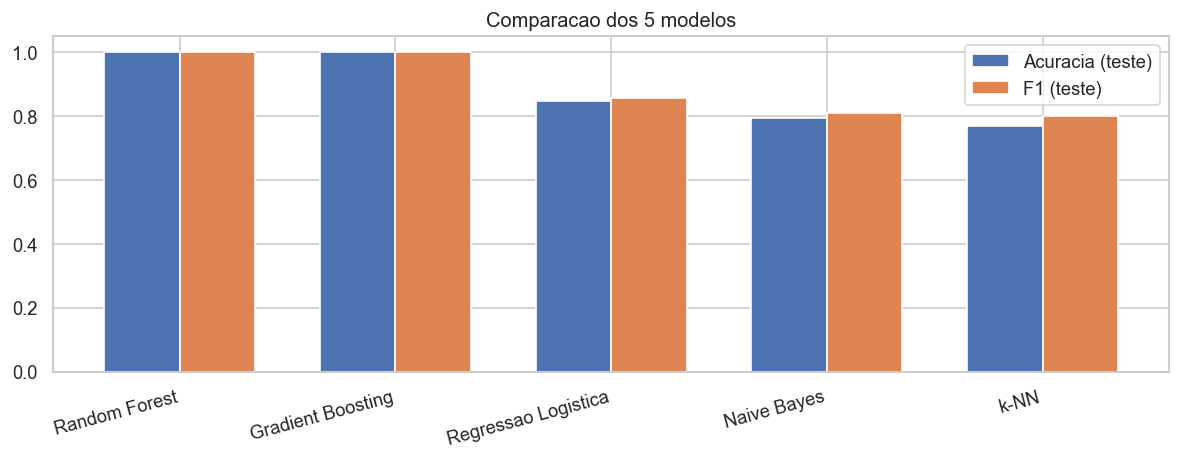

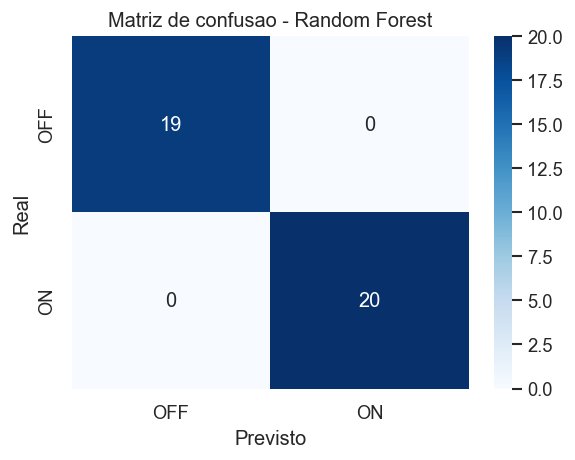

Melhor modelo nesta execucao: Random Forest


In [7]:
plt.figure(figsize=(10, 4))
xax = np.arange(len(resultado))
w = 0.35
plt.bar(xax - w / 2, resultado["Acuracia_teste"], w, label="Acuracia (teste)")
plt.bar(xax + w / 2, resultado["F1_teste"], w, label="F1 (teste)")
plt.xticks(xax, resultado["Modelo"], rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.title("Comparacao dos 5 modelos")
plt.legend()
plt.tight_layout()
plt.show()

melhor_nome = resultado.iloc[0]["Modelo"]
melhor_modelo = modelos[melhor_nome]
pred_best = melhor_modelo.predict(X_test)
cm = confusion_matrix(y_test, pred_best, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["OFF", "ON"], yticklabels=["OFF", "ON"])
plt.title(f"Matriz de confusao - {melhor_nome}")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

print("Melhor modelo nesta execucao:", melhor_nome)


## Parte B — Produtos agrícolas (`Produtos Agricolas (culturas)` no Streamlit)
**Ficheiro:** `src/dados/Atividade_Cap10_produtos_agricolas.csv` (esquema: `N,P,K,temperature,humidity,ph,rainfall,label`).
**Variáveis (enunciado):** N, P, K, temperatura, umidade, pH, chuva, label.
**Objetivo:** classificar **`label`** (cultura) com os mesmos 5 algoritmos da função **`_secao_modelos_produtos`** no dashboard.


In [10]:
dfa = preparar_produtos(carregar_csv(AGRI_CSV_PATH))

print("Repositorio:", REPO)
print("Fonte Parte B: csv_produtos | Arquivo:", AGRI_CSV_PATH)
print("Linhas apos preparo:", len(dfa))

display(dfa.head())
display(dfa.describe().round(2))
print("Distribuicao de classes (label/cultura):")
print(dfa["label"].value_counts())


Repositorio: C:\Users\Georgia\Documents\FIAP_IA\Fase 3\FASE3_AT1_Farmtech_dashboard-main
Fonte Parte B: csv_produtos | Arquivo: C:\Users\Georgia\Documents\FIAP_IA\Fase 3\FASE3_AT1_Farmtech_dashboard-main\src\dados\Atividade_Cap10_produtos_agricolas.csv
Linhas apos preparo: 2200


,N,P,K,temp_c,umidade,ph_corr,chuva,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


,N,P,K,temp_c,umidade,ph_corr,chuva
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


Distribuicao de classes (label/cultura):
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


### 2. EDA (5+ gráficos — títulos como `px.*` da página Streamlit)


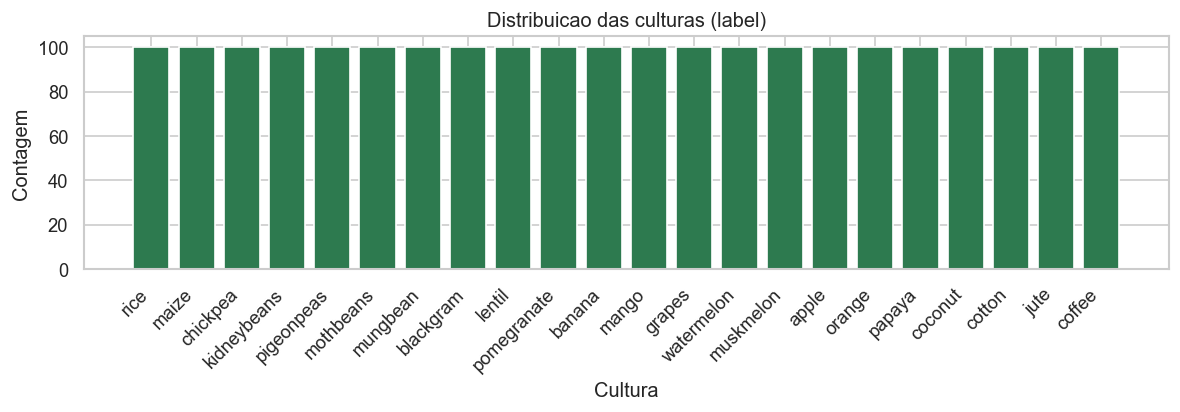

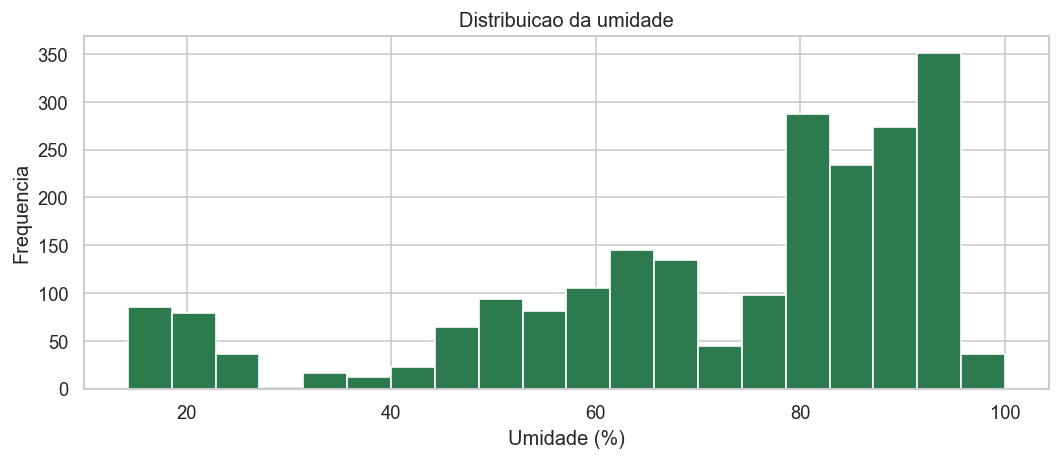

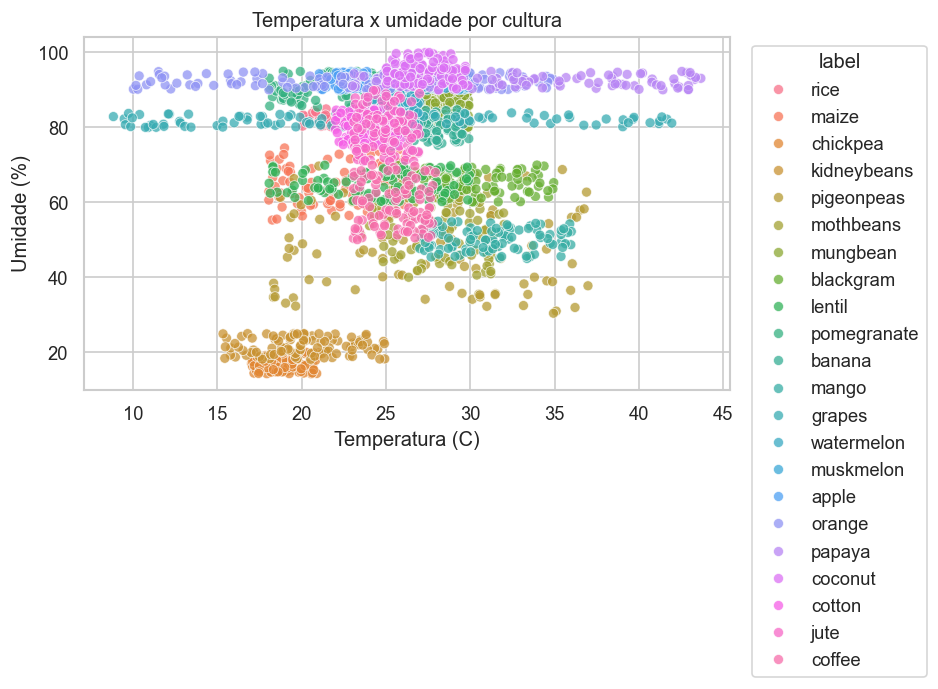

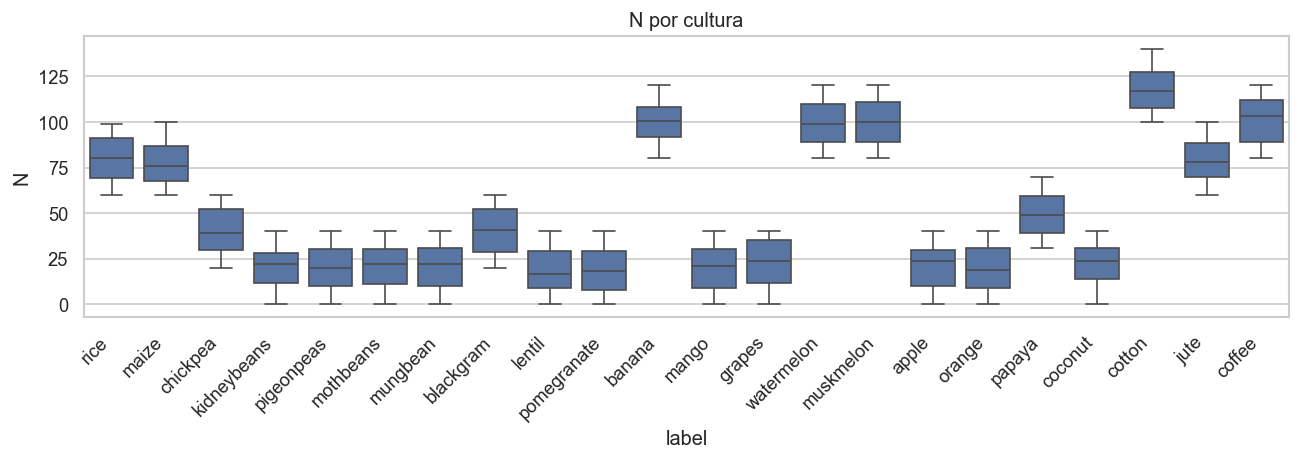

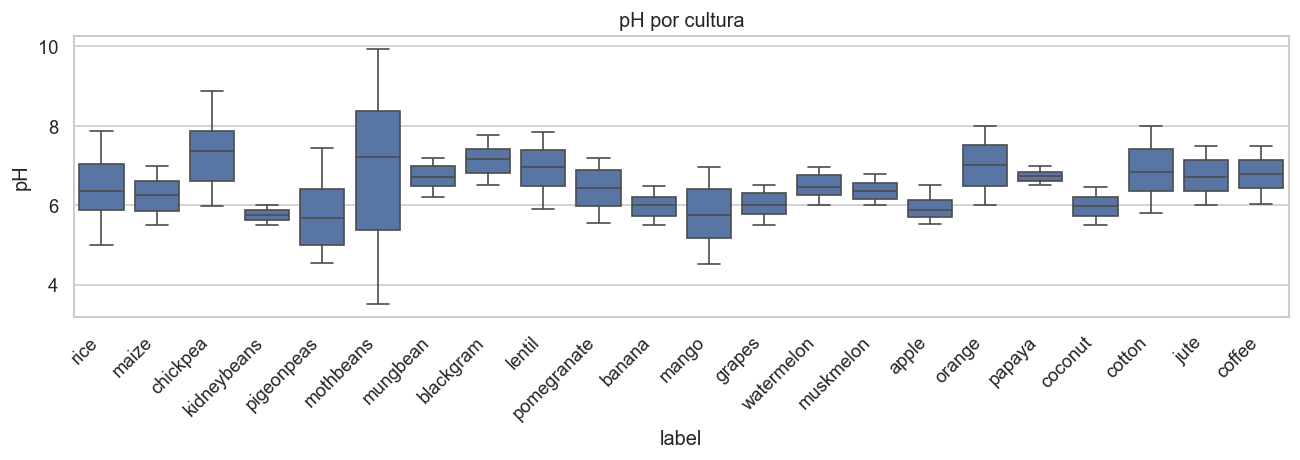

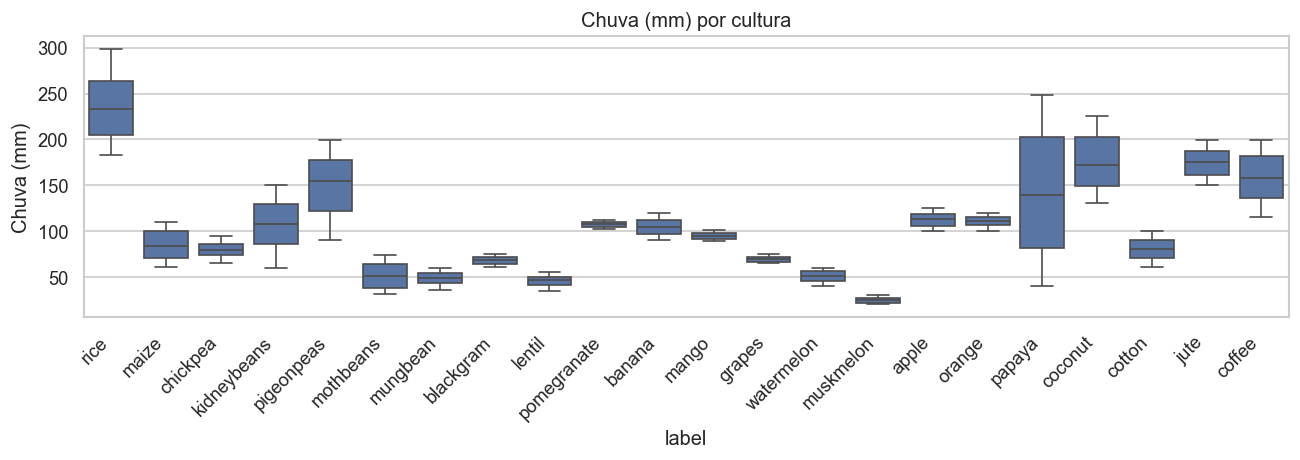

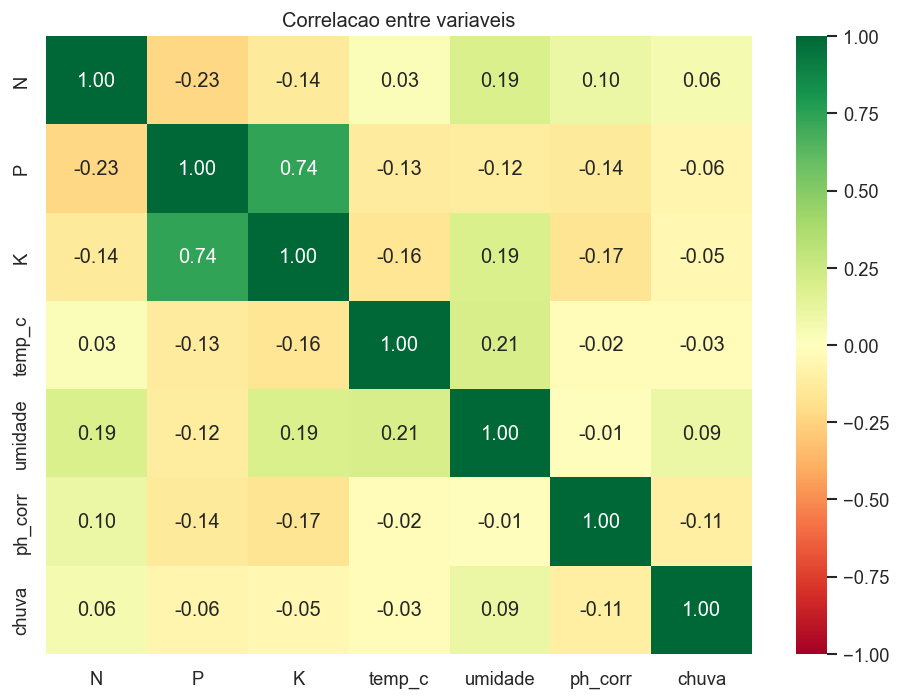

In [11]:
plt.figure(figsize=(10, 3.6))
cfa = dfa["label"].value_counts()
plt.bar(cfa.index.astype(str), cfa.values, color="#2d7a4f", edgecolor="white")
plt.title("Distribuicao das culturas (label)")
plt.xlabel("Cultura")
plt.ylabel("Contagem")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(dfa["umidade"], bins=20, color="#2d7a4f", edgecolor="white")
plt.title("Distribuicao da umidade")
plt.xlabel("Umidade (%)")
plt.ylabel("Frequencia")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=dfa, x="temp_c", y="umidade", hue="label", alpha=0.75)
plt.title("Temperatura x umidade por cultura")
plt.xlabel("Temperatura (C)")
plt.ylabel("Umidade (%)")
plt.legend(title="label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4))
sns.boxplot(data=dfa, x="label", y="N")
plt.xticks(rotation=45, ha="right")
plt.title("N por cultura")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4))
sns.boxplot(data=dfa, x="label", y="ph_corr")
plt.xticks(rotation=45, ha="right")
plt.title("pH por cultura")
plt.ylabel("pH")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4))
sns.boxplot(data=dfa, x="label", y="chuva")
plt.xticks(rotation=45, ha="right")
plt.title("Chuva (mm) por cultura")
plt.ylabel("Chuva (mm)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    dfa[["N", "P", "K", "temp_c", "umidade", "ph_corr", "chuva"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlacao entre variaveis")
plt.tight_layout()
plt.show()


### 3. Perfil ideal de solo/clima — 3 culturas mais frequentes (médias)


,label,N,P,K,temp_c,umidade,ph_corr,chuva
0,chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
1,maize,77.76,48.44,19.79,22.39,65.09,6.25,84.77
2,rice,79.89,47.58,39.87,23.69,82.27,6.43,236.18


,Modelo,Acuracia_teste,F1_ponderado,Acuracia_CV
1,Random Forest,0.9945,0.9945,0.9955
4,Naive Bayes,0.9945,0.9945,0.9945
2,Gradient Boosting,0.9891,0.9891,0.9909
3,k-NN,0.9764,0.9762,0.9705
0,Regressao Logistica,0.9691,0.9688,0.9714


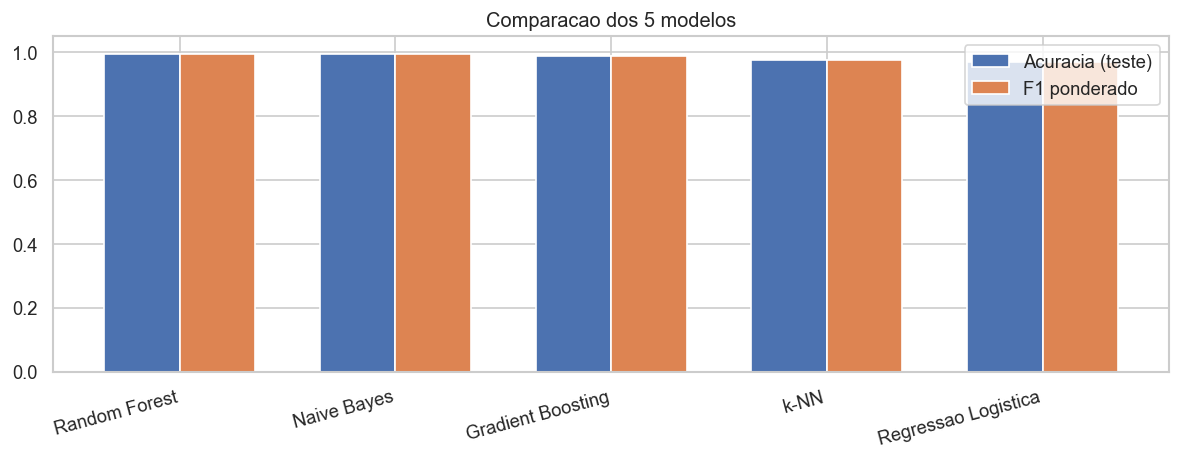

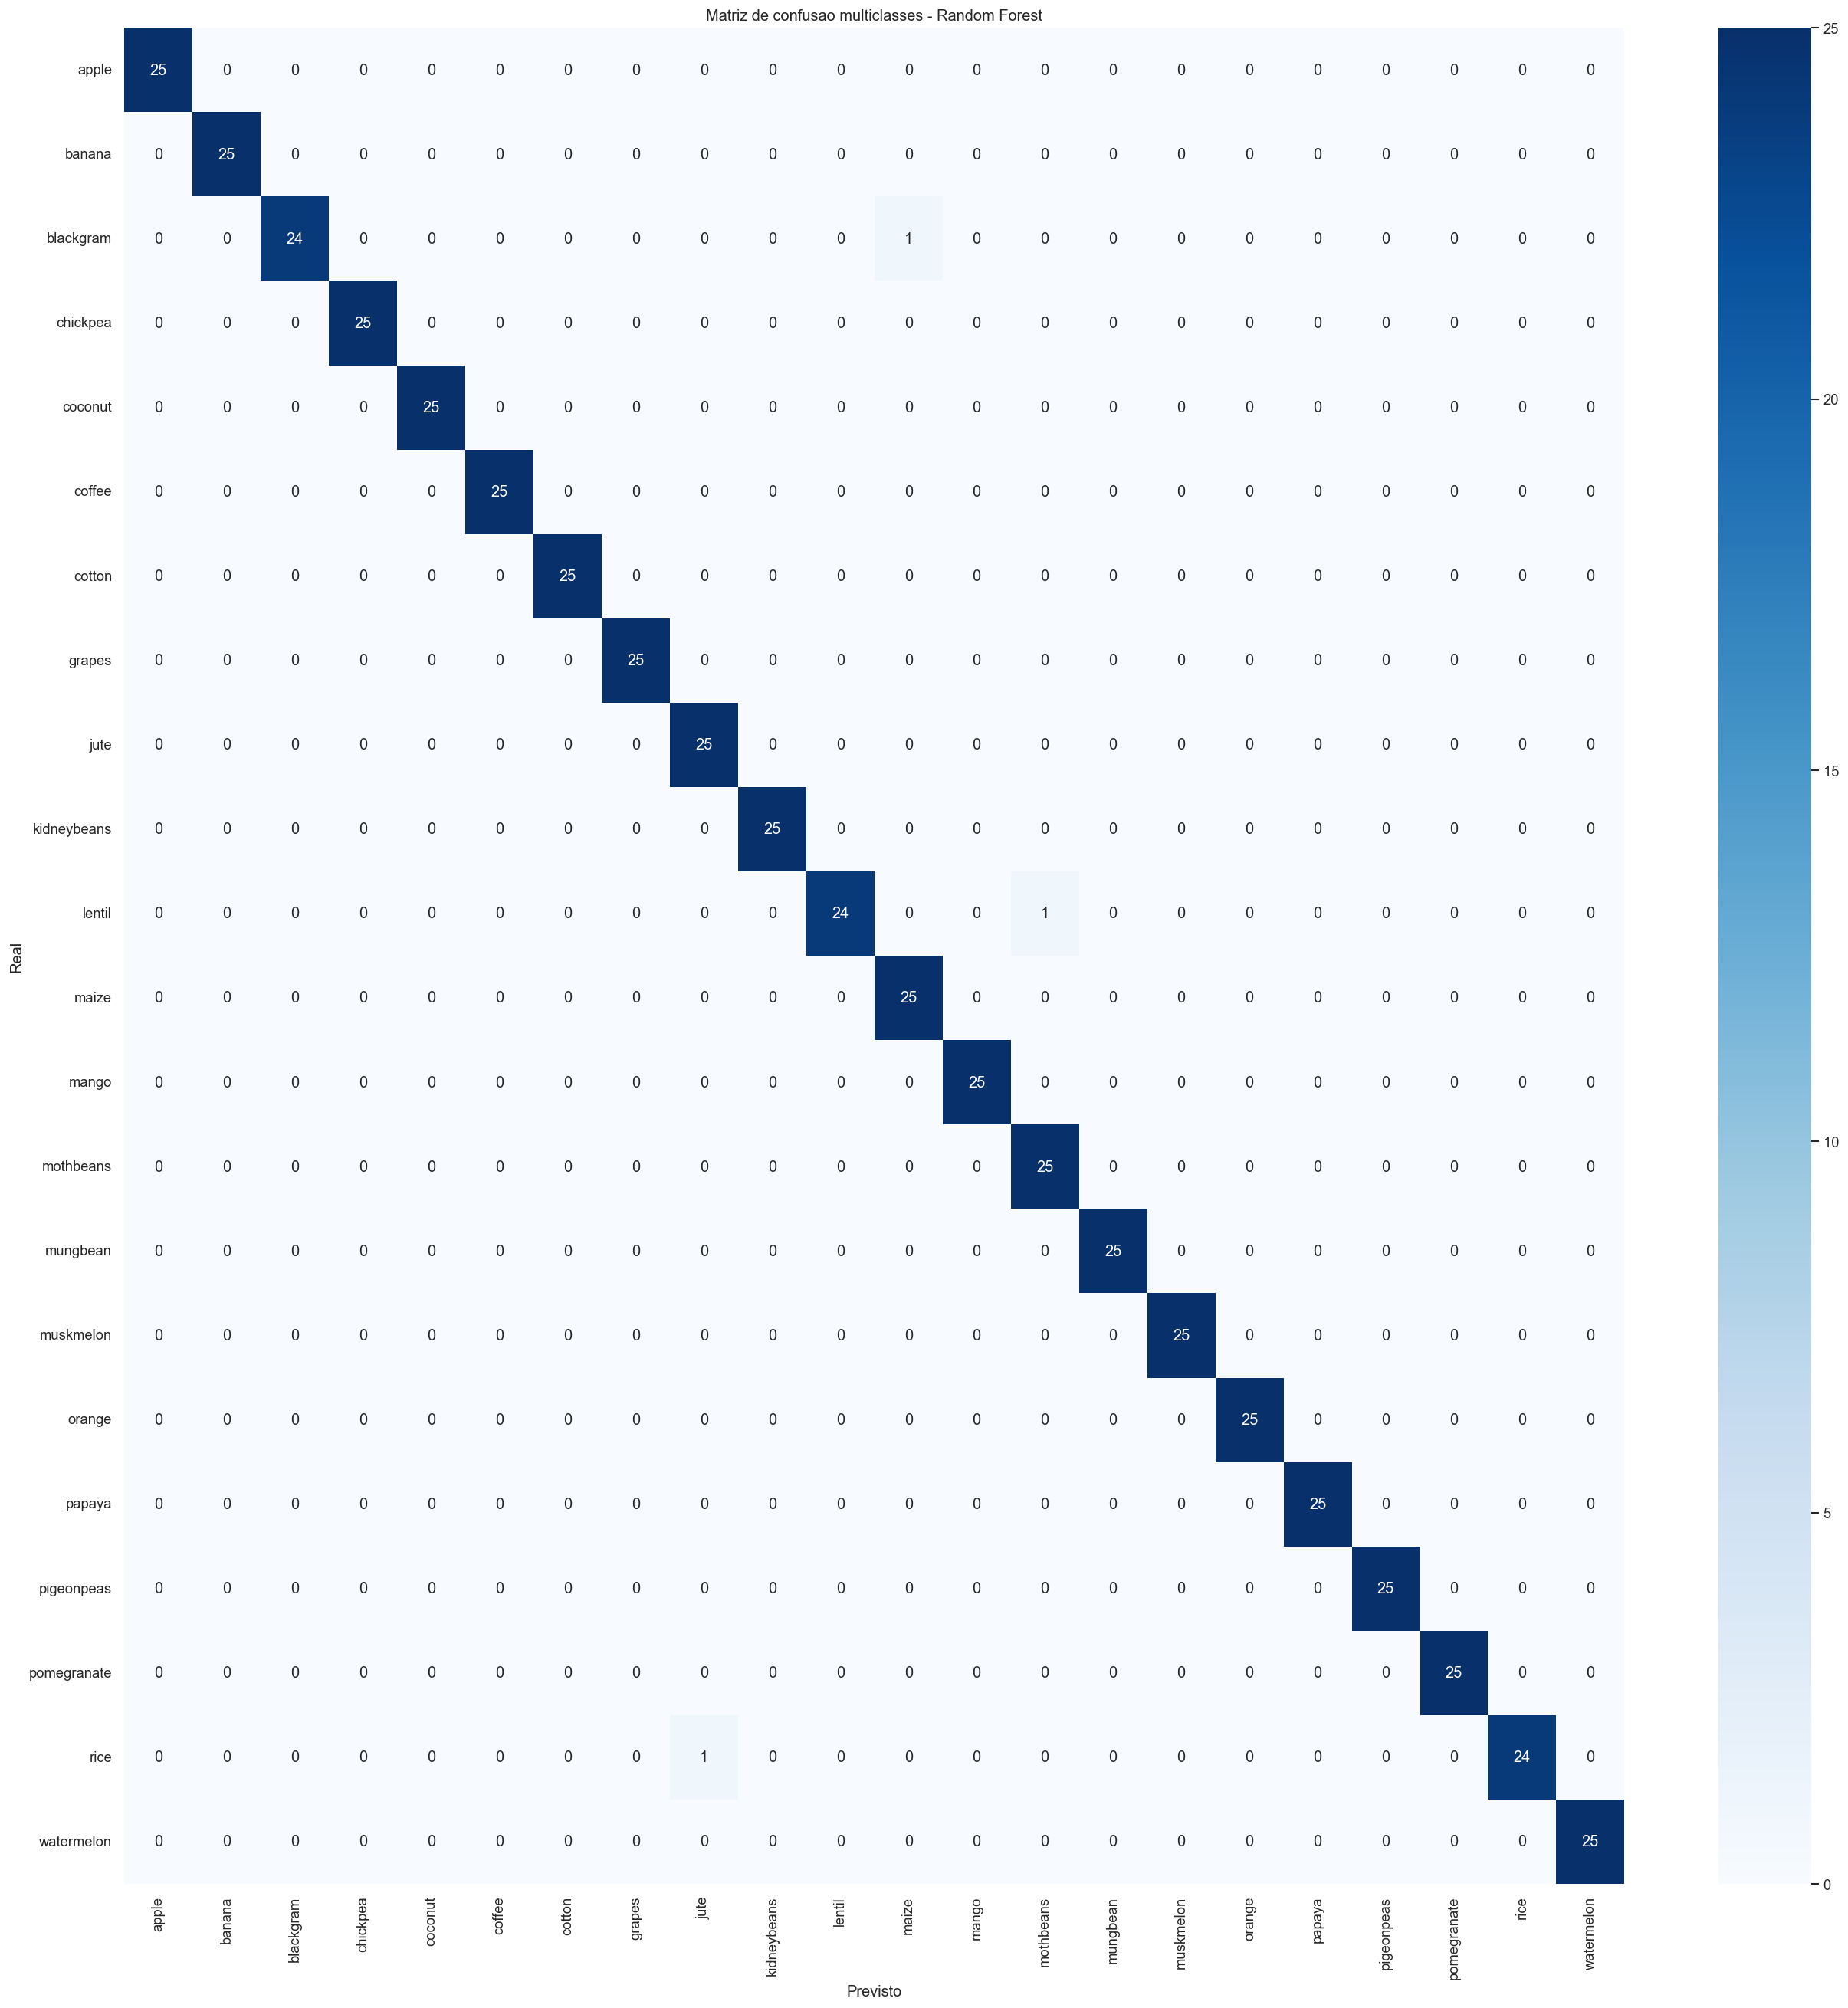

Melhor modelo nesta execucao (Parte B): Random Forest


In [13]:
top3 = dfa["label"].value_counts().head(3).index.tolist()
perfil_b = (
    dfa[dfa["label"].isin(top3)]
    .groupby("label", as_index=False)[["N", "P", "K", "temp_c", "umidade", "ph_corr", "chuva"]]
    .mean()
    .round(2)
)
display(perfil_b)

if len(dfa) < 10:
    raise RuntimeError("Poucas linhas para treinar os 5 modelos (minimo sugerido: 10).")

features_b = ["N", "P", "K", "temp_c", "umidade", "ph_corr", "chuva"]
Xb = dfa[features_b].to_numpy(dtype=float, copy=True)
yb = dfa["label"].astype(str).to_numpy(copy=True)
Xb_scaled = StandardScaler().fit_transform(Xb)
sk_b = {"test_size": 0.25, "random_state": 42}
if pd.Series(yb).value_counts().min() >= 2:
    sk_b["stratify"] = yb
try:
    Xtr, Xte, ytr, yte = train_test_split(Xb_scaled, yb, **sk_b)
except ValueError:
    sk_b.pop("stratify", None)
    Xtr, Xte, ytr, yte = train_test_split(Xb_scaled, yb, **sk_b)

modelos_b = {
    "Regressao Logistica": LogisticRegression(max_iter=1200, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=max(3, min(7, len(Xtr) // 6))),
    "Naive Bayes": GaussianNB(),
}
min_cls_b = int(pd.Series(yb).value_counts().min())
n_splits_b = min(5, min_cls_b) if min_cls_b >= 2 else 0
usar_cv_b = n_splits_b >= 2 and len(yb) >= 10

linhas_b = []
for nome, modelo in modelos_b.items():
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(Xte)
    acc = float(accuracy_score(yte, pred))
    f1w = float(f1_score(yte, pred, average="weighted", zero_division=0))
    cv_acc = float("nan")
    if usar_cv_b:
        cv_b = StratifiedKFold(n_splits=n_splits_b, shuffle=True, random_state=42)
        cv_acc = float(cross_val_score(modelo, Xb_scaled, yb, cv=cv_b, scoring="accuracy").mean())
    linhas_b.append({"Modelo": nome, "Acuracia_teste": acc, "F1_ponderado": f1w, "Acuracia_CV": cv_acc})

resultado_b = pd.DataFrame(linhas_b).sort_values("Acuracia_teste", ascending=False)
display(resultado_b.round(4))

plt.figure(figsize=(10, 4))
xb_ = np.arange(len(resultado_b))
wb = 0.35
plt.bar(xb_ - wb / 2, resultado_b["Acuracia_teste"], wb, label="Acuracia (teste)")
plt.bar(xb_ + wb / 2, resultado_b["F1_ponderado"], wb, label="F1 ponderado")
plt.xticks(xb_, resultado_b["Modelo"], rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.title("Comparacao dos 5 modelos")
plt.legend()
plt.tight_layout()
plt.show()

melhor_b = resultado_b.iloc[0]["Modelo"]
mbest = modelos_b[melhor_b]
pred_b = mbest.predict(Xte)
classes = sorted(pd.Series(yte).astype(str).unique().tolist())
cm_b = confusion_matrix(yte, pred_b, labels=classes)
plt.figure(figsize=(max(9, len(classes)), max(7, len(classes))))
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"Matriz de confusao multiclasses - {melhor_b}")
plt.ylabel("Real")
plt.xlabel("Previsto")
plt.tight_layout()
plt.show()
print("Melhor modelo nesta execucao (Parte B):", melhor_b)
